<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/ES_5_POSITION_OF_STAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Position of a star**

You measure the position of a star $N$
 times with the same telescope i.e. errors are homoscedastic. Let's say the underlying process is Gaussian, the true position is $μ = 1$
 (in suitable units), and the erorrs are $\sigma = 0.2$

In [18]:
import scipy as sc
import numpy as np
from matplotlib import pyplot as plt
np.random.seed(42)


**Part 1**

*  Generate fake measurements. Treat each of these observations as an estimate of the true distribution. So we'll center a Gaussian (with the known $\sigma$) at each point. This is the probability of each data point $p(x_i|\mu,\sigma)$


In [19]:
true_mu= 1
true_sigma=0.2
size_x=1000
size_data=5
data=sc.stats.norm.rvs(loc=true_mu, scale=true_sigma, size=size_data)


*  Plot each of the individual likelihoods separately. Also plot their product $\{x_i\}$ (i.e. the likelihood of the dataset
). Make sure the x grid has enough points.




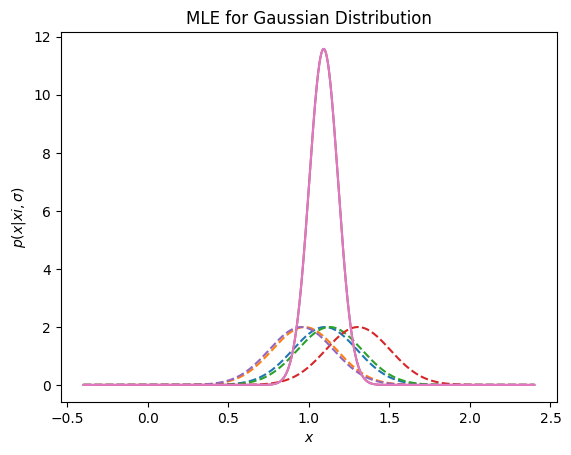

In [20]:
xplot = np.linspace(true_mu-7*true_sigma, true_mu+7*true_sigma, size_x)
joint_pdf=np.ones(size_x)

for xi in data:
  gauss=sc.stats.norm.pdf(xplot,xi,true_sigma)
  joint_pdf=gauss*joint_pdf
  plt.plot(xplot, gauss,ls='--')

#plot
plt.plot(xplot, joint_pdf)
plt.xlabel('$x$')
plt.ylabel(r'$p(x|xi,\sigma)$')
plt.title('MLE for Gaussian Distribution')
plt.plot(xplot, joint_pdf)
plt.show()

*  Just read off the maximum likelihood solution (e.g. using np.argsort)


In [21]:
index_max=np.argsort(joint_pdf)[size_x-1]
MLE_1= xplot[index_max]
print(MLE_1)

1.0910910910910914


*  Compare it with the MLE estimator derived above

In [22]:
MLE_analitic=np.mean(data)
print(MLE_analitic)

1.0918005948650173


**Part 2**






Check the Fisher matrix error estimate makes sense
- do a rough $2^\mathrm{nd}$ order differentation of our log-likelihood function with `np.diff`,
- divide through by our $\Delta \theta^2$ to get the correct normalization,
- multiply by $-1$,
- then take the square root.
- Compare with the Fisher matrix error derived above
- Plot a Gaussian at the measured $\mu$ with this error as the scale to see if it matches the numerical likelihood distribution. (The normalization won't be captured, you can rescale it as you like to check it agrees)


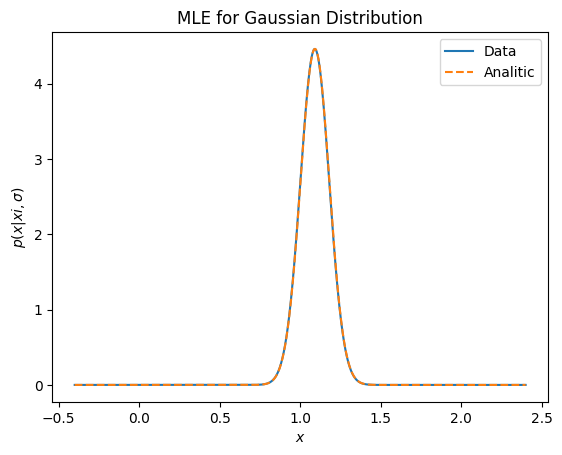

In [23]:
#computation of Fisher matrix error estimate (in mu)
fisherMatrix_data=((-np.diff(np.log(joint_pdf),2))/((xplot[1]-xplot[0])**2))[index_max]
fisherMatrix_data= 1/(np.sqrt(fisherMatrix_data))

#analitic Fisher matrix error estimate for gaussian (in mu)
fisherMatrix_analitic= true_sigma/np.sqrt(size_data)

#plot
plt.plot(xplot,sc.stats.norm.pdf(xplot,MLE_1,fisherMatrix_data), label='Data')
plt.plot(xplot,sc.stats.norm.pdf(xplot,MLE_analitic,fisherMatrix_analitic),ls='--',label='Analitic')
plt.title('MLE for Gaussian Distribution')
plt.xlabel('$x$')
plt.ylabel(r'$p(x|xi,\sigma)$')
plt.legend()
plt.show()